# Laboratorio 3 - Clasificación

**Curso:** ISIS2611 - Aprendizaje de Máquina **Caso:** Ruta Alpes

**Integrantes:** Samuel Andres Molina Luna, Daniel Esteban Pardo Pardo

Ruta Alpes es una aplicación de asistencia de conducción que recomienda cupones a los conductores mientras se desplazan. Este laboratorio construye modelos de clasificación para anticipar si un conductor **aceptará** (`acepta_cupon` = Sí / No) un cupón de **Cafetería** o de **Restaurante(<20)**, y evalúa los riesgos de sesgo de personalizar ofertas con datos demográficos.

**Objetivos**
* Comparar regresión logística, árboles de decisión y Random Forest para cada tipo de cupón.
* Evaluar si el desbalance de clases afecta el desempeño y si una técnica de balanceo lo mejora.
* Reconocer posibles sesgos al usar variables demográficas para personalización.
* Comunicar los resultados y sustentar las decisiones metodológicas.

## 1. Carga de datos y librerias

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, precision_score, recall_score, f1_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

### Cargar datos a dataframe

In [2]:
data = pd.read_excel('data/Lab3_Datos.xlsx')
df_Base = data.copy()
df_Base.shape
df_Base.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
0,Sin lugar urgente,Solo,Soleado,55,2:00 p.m.,Restaurante(<20),1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No,Sí,No
2,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Comida para llevar,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,Sí
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,nunca,NaN,4 a 8,1 a 3,Sí,Sí,No,No,Sí,No


In [3]:
# Dataset de prueba (sin etiqueta)
df_test = pd.read_excel('data/Lab3_datos_Prueba.xlsx')
df_test.head()

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta
0,Trabajo,Solo,Soleado,55,7:00 a.m.,Cafetería,2 horas,Femenino,50 o más,Divorciado(a),...,1 a 3,4 a 8,4 a 8,4 a 8,menos de 1,Sí,Sí,No,No,Sí
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,31,Unión libre,...,menos de 1,1 a 3,más de 8,4 a 8,1 a 3,Sí,No,No,No,Sí
2,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,31,Soltero(a),...,menos de 1,1 a 3,4 a 8,más de 8,menos de 1,Sí,Sí,No,No,Sí
3,Sin lugar urgente,Pareja,Soleado,80,10:00 a.m.,Cafetería,2 horas,Masculino,50 o más,Casado(a),...,nunca,más de 8,nunca,4 a 8,menos de 1,Sí,No,No,No,Sí
4,Sin lugar urgente,Amigo(s),Soleado,80,6:00 p.m.,Restaurante(<20),2 horas,Femenino,26,Soltero(a),...,1 a 3,menos de 1,4 a 8,menos de 1,4 a 8,Sí,Sí,No,No,Sí


# 2. Exploración de los datos

Aqui se analizan por separado los dos subconjuntos del caso que son los registros del cupon **Cafeteria** y los del cupon **Restaurante(<20)**. El objetivo es entender la variable objetivo `acepta_cupon` y diagnosticar la calidad de los datos.

**2.1 Visión general**

Se revisa el tamaño del conjunto, el tipo de dato de cada columna y un resumen estadistico para tener una primera idea de las variables.

In [4]:
print(df_Base.shape)
df_Base.dtypes

(12664, 26)


destino                              str
acompanante                          str
clima                                str
temperatura                        int64
hora                                 str
cupon                                str
vigencia_cupon                       str
genero                               str
edad                                 str
estado_civil                         str
tiene_hijos                          str
educacion                            str
ocupacion                            str
ingreso                              str
vehiculo                             str
frecuencia_bar                       str
frecuencia_cafeteria                 str
frecuencia_comida_para_llevar        str
frecuencia_restaurante_menos_20      str
frecuencia_restaurante_20_a_50       str
tiempo_cupon_mayor_5min              str
tiempo_cupon_mayor_15min             str
tiempo_cupon_mayor_25min             str
misma_direccion                      str
direccion_opuest

In [5]:
df_Base.describe(include='all')

,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664.000000,12664,12664,12664,12664,12664,12664,...,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,NaN,5,5,2,2,8,5,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,NaN,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,NaN,3224,3986,7081,6501,2652,5092,...,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196
mean,NaN,NaN,NaN,63.287271,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,19.158130,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,30.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,80.000000,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2.2 Calidad de datos y separacion por tipo de cupon y distribucion de `acepta_cupon`

El enunciado pide trabajar solo con los cupones Cafeteria y Restaurante(<20) por lo que se separa cada subconjunto y se mira cuantos registros tiene y que proporcion acepta el cupon, para saber si las clases estan balanceadas.

In [6]:
cafe = df_Base[df_Base['cupon'] == 'Cafetería'].copy()
rest = df_Base[df_Base['cupon'] == 'Restaurante(<20)'].copy()

for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(nombre, s.shape)
    print(s['acepta_cupon'].value_counts())
    print(s['acepta_cupon'].value_counts(normalize=True).round(3), '\n')

Cafetería (3986, 26)
acepta_cupon
No    1997
Sí    1989
Name: count, dtype: int64
acepta_cupon
No    0.501
Sí    0.499
Name: proportion, dtype: float64 

Restaurante(<20) (2776, 26)
acepta_cupon
Sí    1962
No     814
Name: count, dtype: int64
acepta_cupon
Sí    0.707
No    0.293
Name: proportion, dtype: float64 



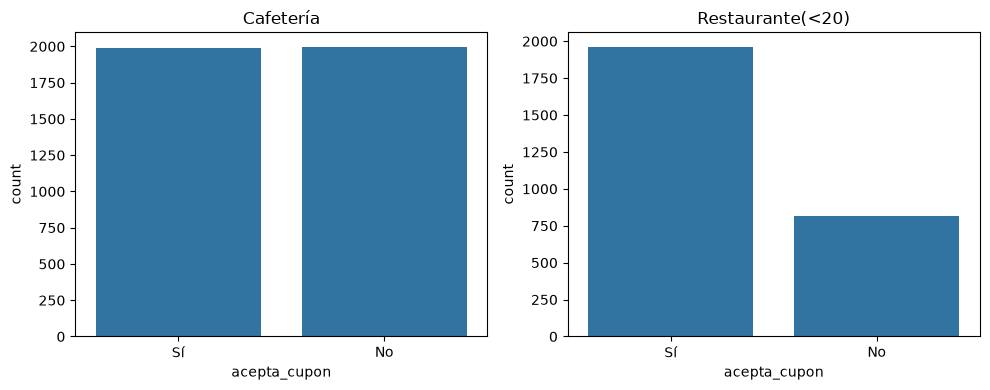

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (nombre, s) in zip(axes, [('Cafetería', cafe), ('Restaurante(<20)', rest)]):
    sns.countplot(data=s, x='acepta_cupon', order=['Sí', 'No'], ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

Aqui analizamos lo siguiente:
- **Cafetería** (3.986 registros): las clases estan practicamente balanceadas con 1.989 "Si" que es un 49,9 % y 1.997 "No" con 50,1 %. No se necesita balanceo y la exactitud es una metrica razonable, aunque se reportaran tambien precisión, recall y F1.
- **Restaurante(<20)** (2.776 registros): hay un desbalance moderado, con 1.962 "Sí" (70,7 %) y 814 "No" (29,3 %). La clase minoritaria es "No" que son quienes rechazan el cupon.
- **Implicación para el modelado:** en Restaurante(<20), un modelo que prediga siempre "Si" obtendria 70,7 % de accuracy sin aprender nada, es por esto que la accuracy engaña y se debe evaluar con F1 y con el recall de la clase minoritaria.

**2.3 Valores nulos**

Se calcula la cantidad y el porcentaje de valores nulos por columna en cada subconjunto (Cafeteria y Restaurante(<20)).

In [8]:
nulos = pd.DataFrame({
    'Cafetería (n)': cafe.isna().sum(),
    'Cafetería (%)': (cafe.isna().mean() * 100).round(2),
    'Restaurante(<20) (n)': rest.isna().sum(),
    'Restaurante(<20) (%)': (rest.isna().mean() * 100).round(2),
})
nulos[(nulos['Cafetería (n)'] > 0) | (nulos['Restaurante(<20) (n)'] > 0)]

,Cafetería (n),Cafetería (%),Restaurante(<20) (n),Restaurante(<20) (%)
vehiculo,3949,99.07,2751,99.10
frecuencia_bar,37,0.93,23,0.83
frecuencia_cafeteria,72,1.81,47,1.69
frecuencia_comida_para_llevar,57,1.43,34,1.22
frecuencia_restaurante_menos_20,50,1.25,27,0.97
frecuencia_restaurante_20_a_50,55,1.38,43,1.55


Vemos que **`vehiculo`** tiene un 99 % de valores nulos en ambos subconjuntos (3.949 de 3.986 en Cafeteria y 2.751 de 2.776 en Restaurante(<20)). como tiene tan pocos datos no es posible imputarla de forma confiable, y en el archivo de prueba tambien esta vacia, asi que no aportaria nada al modelo. **Las cinco variables de frecuencia** tienen pocos nulos, entre 0,83 % y 1,81 %. Con esta proporcion no se justifica eliminar filas por lo que se imputaran con la moda dentro del Pipeline. Ninguna otra variable presenta valores nulos incluida la variable objetivo `acepta_cupon`, por lo que no hay registros sin etiqueta que descartar.

**2.4 Estadísticas descriptivas**

Se resumen las variables del conjunto completo (12.664 registros antes de separar por cupon). Primero la unica variable numerica `temperatura` y luego las variables categoricas, donde interesa el número de categorías (`unique`) y el valor más frecuente (`top`, `freq`).

In [9]:
df_Base.describe()

,temperatura
count,12664.000000
mean,63.287271
std,19.158130
min,30.000000
25%,55.000000
50%,80.000000
75%,80.000000
max,80.000000


In [10]:
df_Base.describe(exclude='number')

,destino,acompanante,clima,hora,cupon,vigencia_cupon,genero,edad,estado_civil,tiene_hijos,...,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_5min,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,direccion_opuesta,acepta_cupon
count,12664,12664,12664,12664,12664,12664,12664,12664,12664,12664,...,12447,12513,12534,12475,12664,12664,12664,12664,12664,12664
unique,3,4,3,5,5,2,2,8,5,2,...,5,5,5,5,1,2,2,2,2,2
top,Sin lugar urgente,Solo,Soleado,6:00 p.m.,Cafetería,1 día,Femenino,21,Casado(a),No,...,menos de 1,1 a 3,1 a 3,menos de 1,Sí,Sí,No,No,Sí,Sí
freq,6270,7296,10052,3224,3986,7081,6501,2652,5092,7421,...,3378,4665,5368,6066,12664,7113,11153,9944,9944,7196


- **`temperatura`** es la unica variable numerica y solo toma tres valores 30, 55 y 80 °F, con media de 63,28. En la practica se comporta como una variable categorica ordenad y no como una medicion continua.
- **`vehiculo`** tiene solo 108 registros no nulos de 12.664 asi como lo vimos anteriormente.
- **`tiempo_cupon_mayor_5min`** tiene un unico valor ("Sí") en todos los registros por lo que es constante y no aporta informacion.
- **`misma_direccion` y `direccion_opuesta`** tienen la misma frecuencia en su valor mas comun que es 9.944, lo que sugiere que son complementarias.
- **`ocupacion`** tiene 25 categorias, la variable de mayor cardinalidad
- **`edad`** (8 niveles), **`ingreso`** (9) y **`educacion`** (6) son categorias con un orden natural y `hora` (5 niveles) y las variables `frecuencia_*` también lo tienen, por lo que se codificaran de forma ordinal.
- **`cupon`** tiene 5 categorias en el conjunto completo aunque en el lab se trabaja solo con Cafeteria (3.986 registros) y Restaurante(<20) (2.776).

**2.5 Duplicados**

Se revisa si existen filas completamente identicas tanto en el conjunto completo como en cada subconjunto.

In [11]:
print('Duplicados exactos en el conjunto completo:', df_Base.duplicated().sum())
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(f'{nombre}: {s.duplicated().sum()} de {len(s)} filas ({s.duplicated().mean()*100:.2f} %)')

Duplicados exactos en el conjunto completo: 74
Cafetería: 7 de 3986 filas (0.18 %)
Restaurante(<20): 7 de 2776 filas (0.25 %)


El conjunto completo tiene 74 filas duplicadas exactas. En cada subconjunto hay 7 lo cual es una proporcion muy pequeña, tambien los datos no incluyen un identificador de registro por lo que no es posible saber si un duplicado es una copia accidental o dos conductores distintos con exactamente las mismas respuestas. Como el efecto sobre el tamaño del conjunto es minimo y se evita el riesgo de fuga entre entrenamiento y prueba se eliminaran en la etapa de preparacion.

**2.6 Relación de las variables explicativas con `acepta_cupon`**

Para identificar qué variables parecen mas relacionadas con la aceptación del cupon se cruza cada variable con `acepta_cupon` mediante tablas de contingencia normalizadas por fila. Asi se obtiene para cada categoria el porcentaje de conductores que aceptan y que rechazan lo cual permite comparar categorias aunque tengan distinto numero de registros. Se hace por separado en Cafeteria y en Restaurante(<20). Se revisan por grupos: contexto del viaje, perfil del conductor y habitos de consumo.

In [12]:
orden_hora = ['7:00 a.m.', '10:00 a.m.', '2:00 p.m.', '6:00 p.m.', '10:00 p.m.']

for col in ['destino', 'acompanante', 'clima', 'hora', 'vigencia_cupon']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col == 'hora':
            tabla = tabla.reindex(orden_hora)
        print(f'{col} - {nombre}')
        print(tabla.round(2), '\n')

destino - Cafetería
acepta_cupon         No    Sí
destino                      
Casa               0.64  0.36
Sin lugar urgente  0.42  0.58
Trabajo            0.55  0.45 

destino - Restaurante(<20)
acepta_cupon         No    Sí
destino                      
Casa               0.44  0.56
Sin lugar urgente  0.21  0.79
Trabajo            0.42  0.58 

acompanante - Cafetería
acepta_cupon    No    Sí
acompanante             
Amigo(s)      0.40  0.60
Hijo(s)       0.52  0.48
Pareja        0.43  0.57
Solo          0.56  0.44 

acompanante - Restaurante(<20)
acepta_cupon    No    Sí
acompanante             
Amigo(s)      0.20  0.80
Hijo(s)       0.28  0.72
Pareja        0.23  0.77
Solo          0.36  0.64 

clima - Cafetería
acepta_cupon    No    Sí
clima                   
Lluvioso      0.48  0.52
Nevado        0.57  0.43
Soleado       0.50  0.50 

clima - Restaurante(<20)
acepta_cupon    No    Sí
clima                   
Lluvioso      0.61  0.39
Nevado        0.51  0.49
Soleado       0.23  

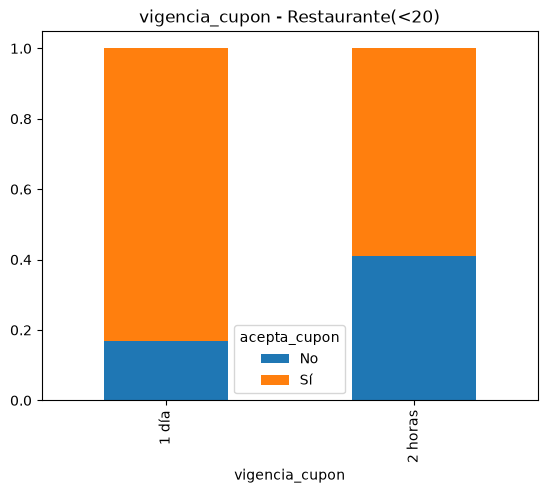

In [13]:
tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
plt.show()

**2.6.2 Perfil del conductor**

Aqui vemos las variables demograficas del conductor como genero, edad, estado civil, si tiene hijos, nivel educativo e ingreso. Las que tienen un orden natural como por ejemplo edad, educación, ingreso se muestran en ese orden.

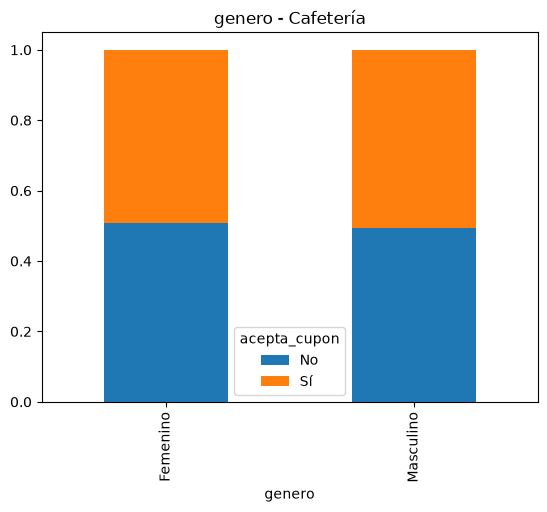

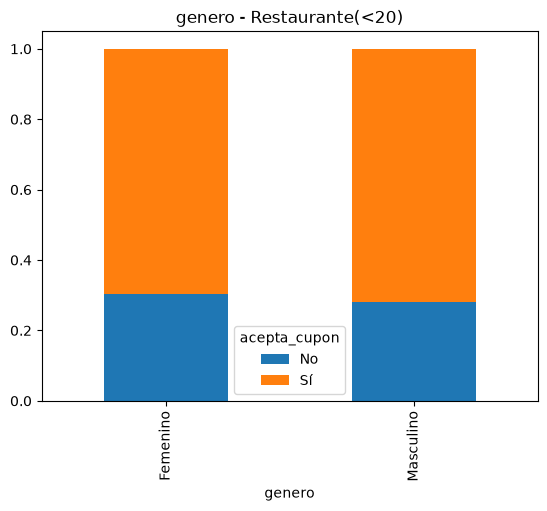

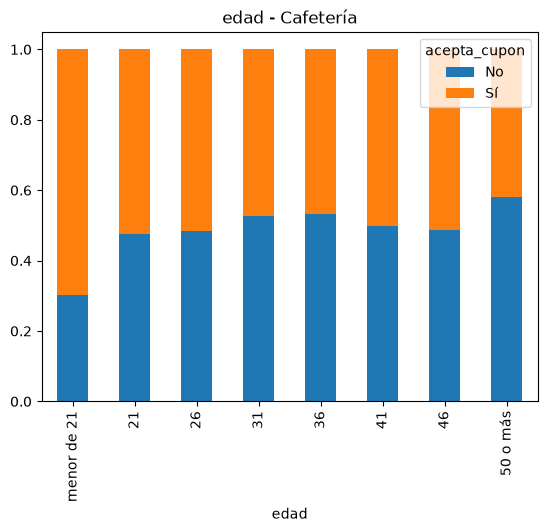

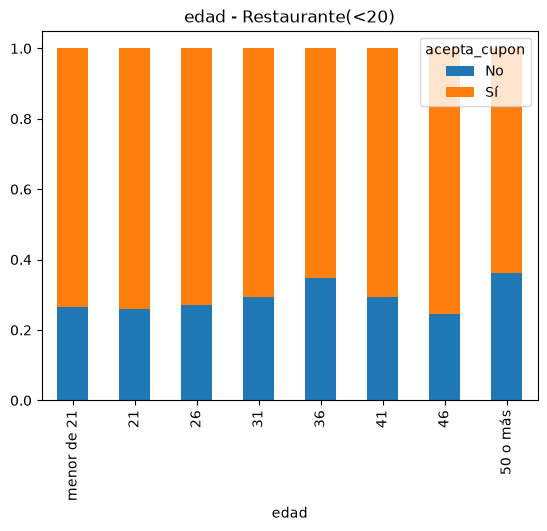

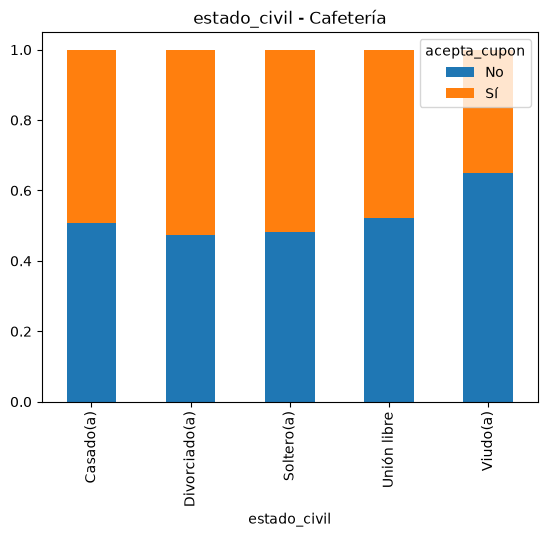

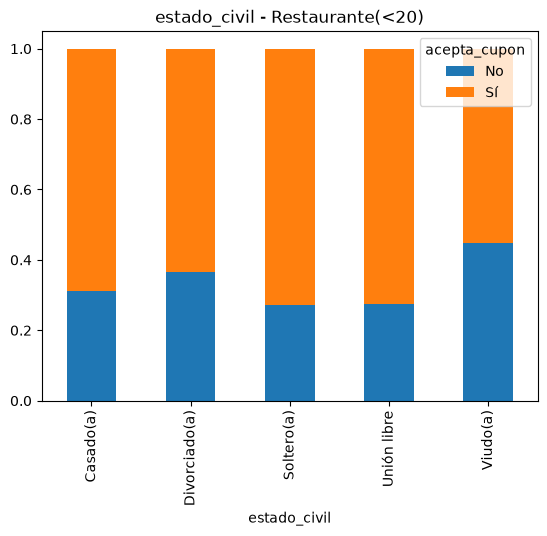

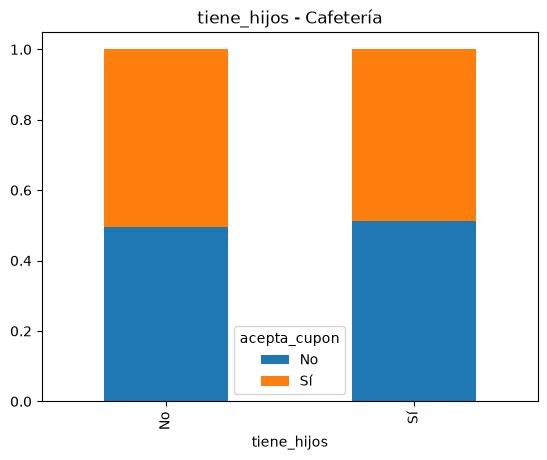

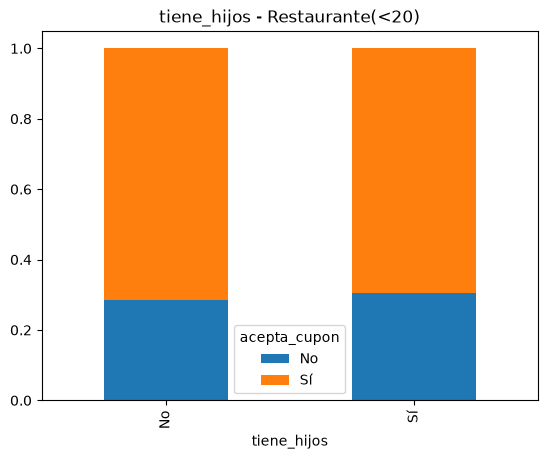

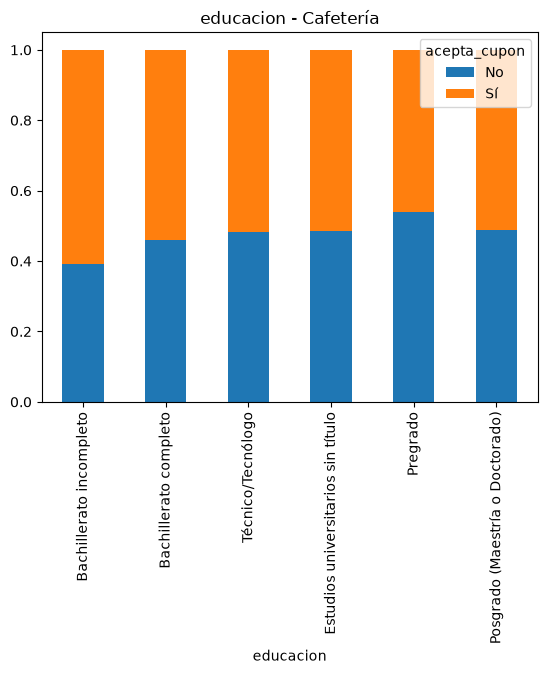

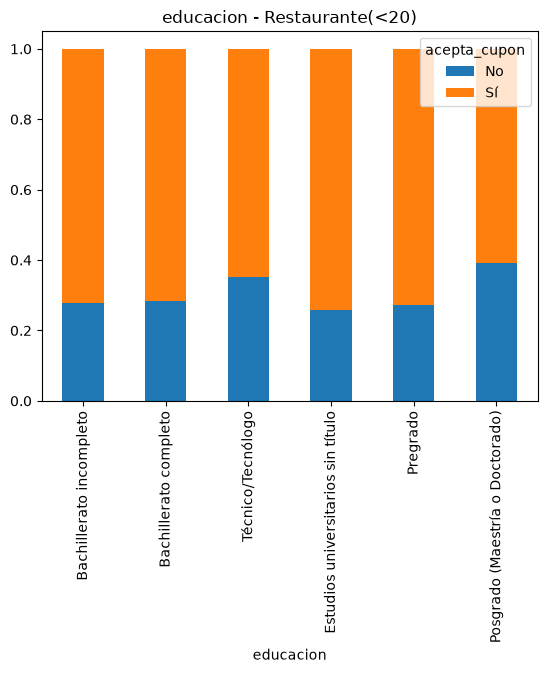

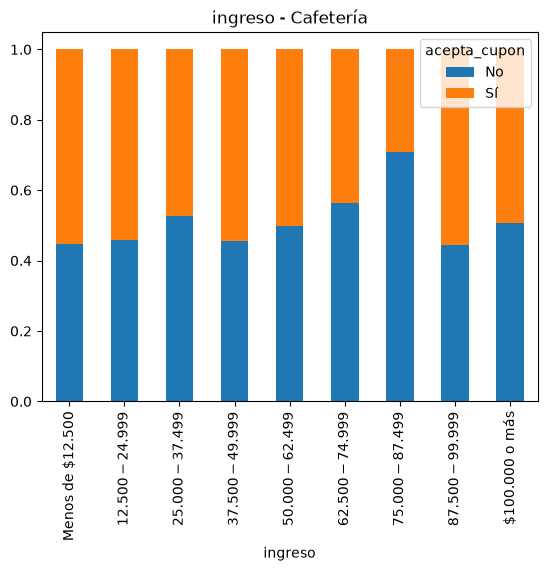

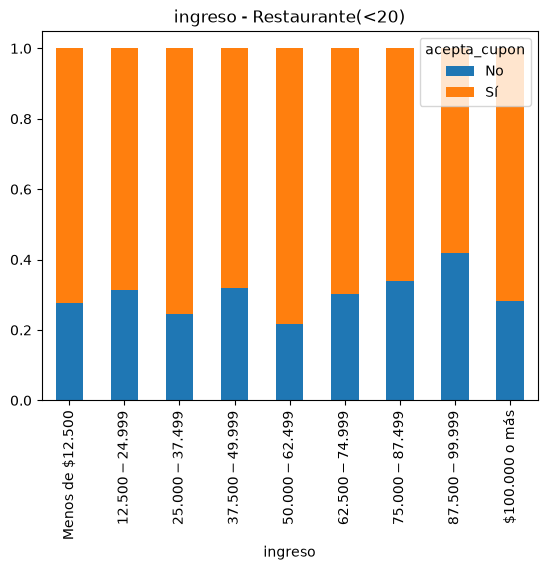

In [14]:
orden_edad = ['menor de 21', '21', '26', '31', '36', '41', '46', '50 o más']
orden_educacion = ['Bachillerato incompleto', 'Bachillerato completo', 'Técnico/Tecnólogo',
                   'Estudios universitarios sin título', 'Pregrado', 'Posgrado (Maestría o Doctorado)']
orden_ingreso = ['Menos de $12.500', '$12.500 - $24.999', '$25.000 - $37.499', '$37.500 - $49.999',
                 '$50.000 - $62.499', '$62.500 - $74.999', '$75.000 - $87.499',
                 '$87.500 - $99.999', '$100.000 o más']
ordenes = {'edad': orden_edad, 'educacion': orden_educacion, 'ingreso': orden_ingreso}

for col in ['genero', 'edad', 'estado_civil', 'tiene_hijos', 'educacion', 'ingreso']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col in ordenes:
            tabla = tabla.reindex(ordenes[col])
        tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
        plt.show()

In [15]:
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    tabla = pd.crosstab(s['ocupacion'], s['acepta_cupon'], normalize='index')['Sí'].sort_values()
    print(nombre)
    print(tabla.round(2), '\n')

Cafetería
ocupacion
Servicios Comunitarios y Sociales                    0.35
Producción                                           0.36
Área Legal                                           0.38
Ventas y afines                                      0.39
Jubilado(a)                                          0.40
Apoyo Administrativo y de Oficina                    0.43
Educación, Formación y Bibliotecología               0.44
Preparación y Servicio de Alimentos                  0.45
Servicios de Protección y Seguridad                  0.45
Gerencia                                             0.46
Ciencias Naturales y Sociales                        0.48
Construcción y Extracción                            0.48
Negocios y Finanzas                                  0.48
Cuidado Personal y Servicios                         0.50
Computación y Matemáticas                            0.50
Artes, Diseño, Entretenimiento, Deportes y Medios    0.51
Desempleado(a)                                      

Se muestran diferencias menores que las del contexto del viaje ya que el genero y el hecho de tener hijos casi no cambian la aceptacion por lo que no nos dan tanta informacion por si solas. La edad si tiene un efecto en cafeteria donde los menores de 21 años aceptan mas (70 %) y los de 50 años o mas menos con un 42 %, mientras que en restaurante(<20) la variacion es pequeña entre 64 % y 76 % y sin una tendencia clara. 

En el estado civil los viudos aceptan menos en ambos cupones con 35 % en cafeteria y 55 % en restaurante(<20), aunque se trata de una categoria pequeña y la diferencia debe tenerse en cuenta, el nivel educativo y el ingreso presentan diferencias moderadas y sin un patron en donde crezca o decrezca de forma constante y se ve en cafeteria donde la aceptacion no sube ni baja de manera constante con el ingreso y llega a un mínimo de 29 % en el rango 75.000 a 87.499. 

Ya por ulitmo la ocupacion es la variable demografica con mas variacion donde en cafeteria va de cerca de 35 % en servicios comunitarios y sociales a cerca de 74 % en profesionales y tecnicos de la salud pero tiene 25 categorías y algunas cuentan con muy pocos registros por ejemplo, 11 en limpieza y mantenimiento de edificios en cafeteria.

**2.6.3 Habitos de consumo y caracteristicas del cupon**

Se revisa la frecuencia con la que el conductor visita distintos tipos de establecimientos (frecuencia) y las variables que describen que tan lejos y en que direccion queda el lugar del cupon (`misma_direccion`, `tiempo_cupon_mayor_15min`, `tiempo_cupon_mayor_25min`).

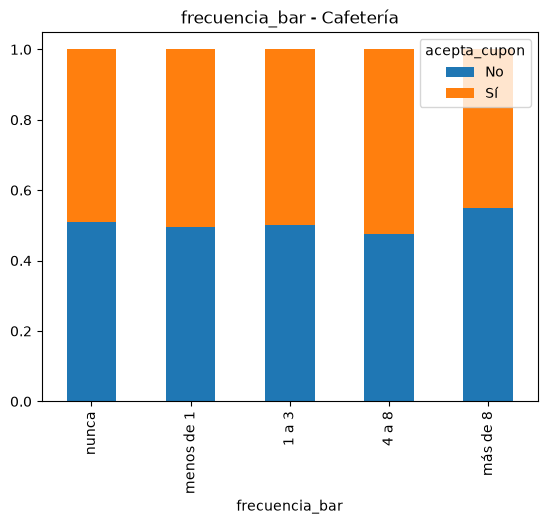

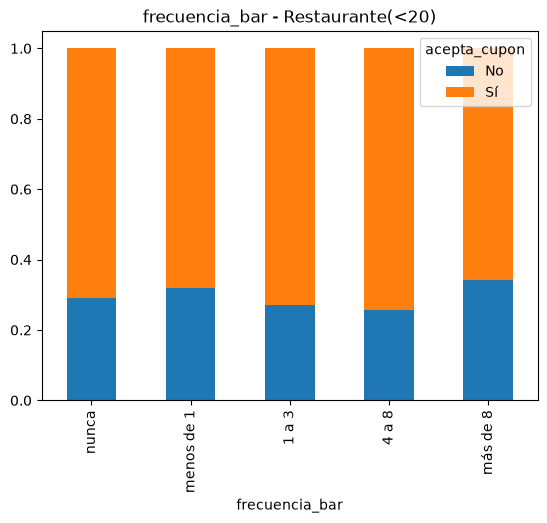

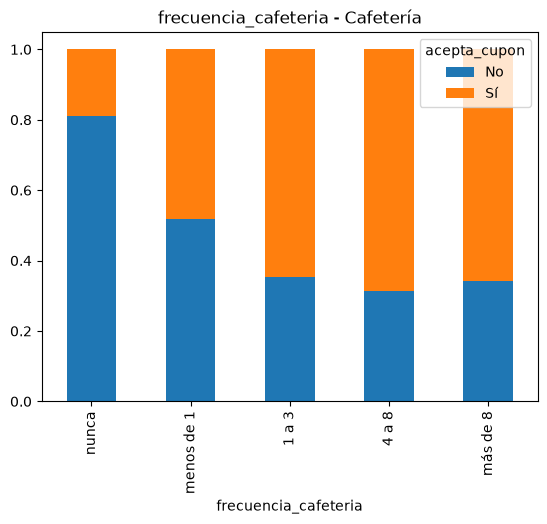

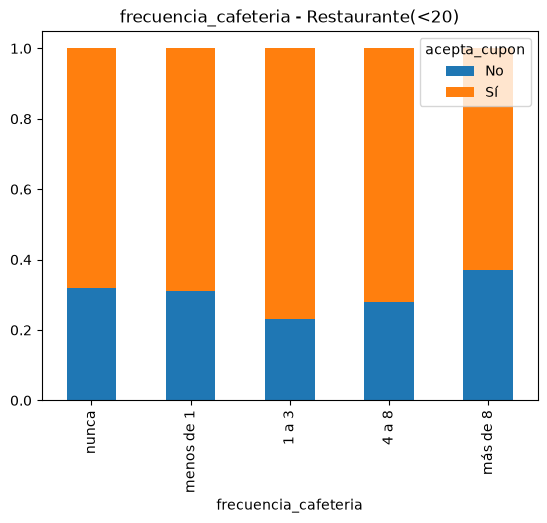

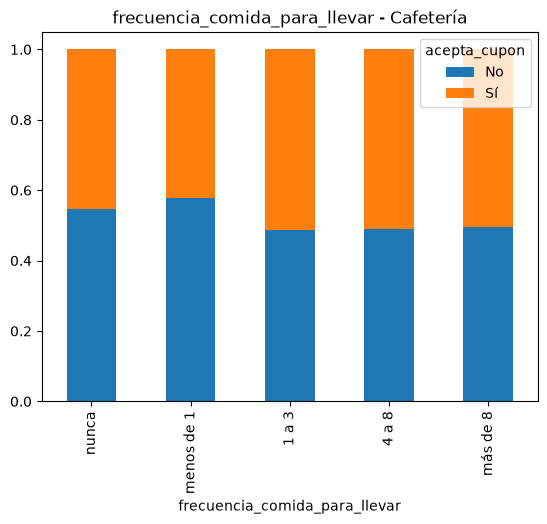

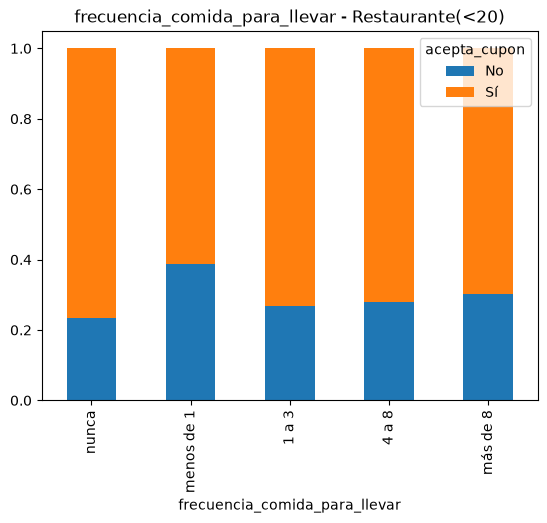

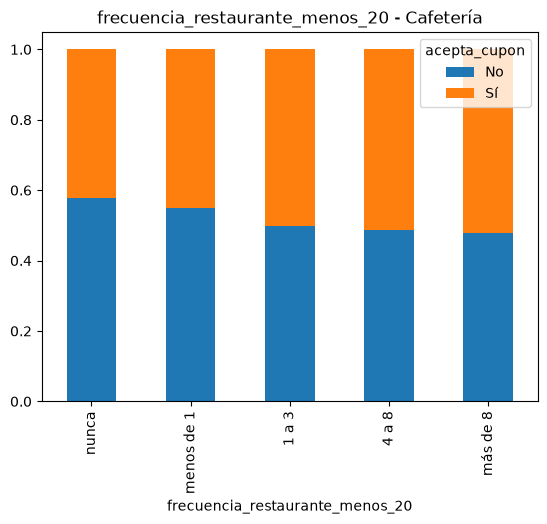

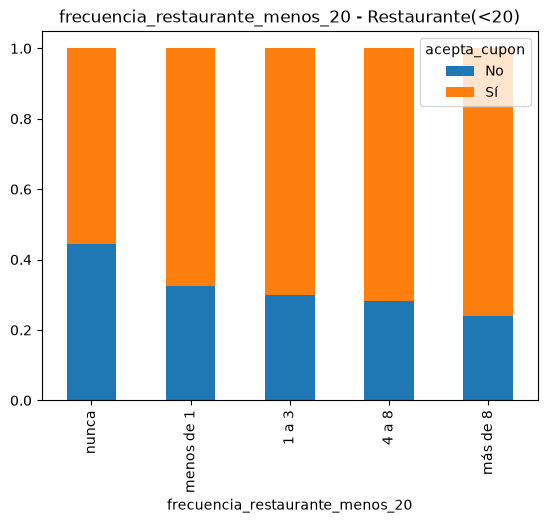

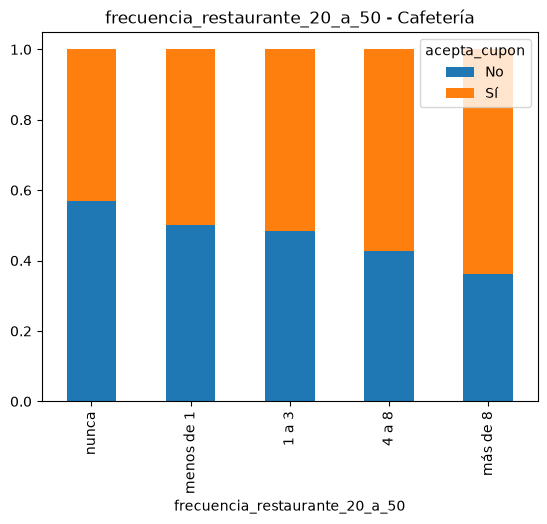

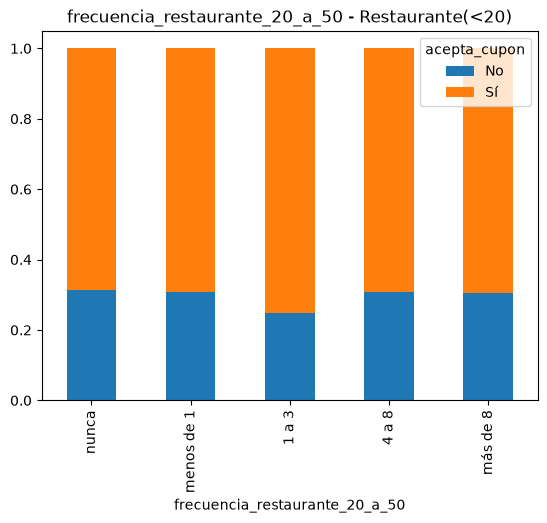

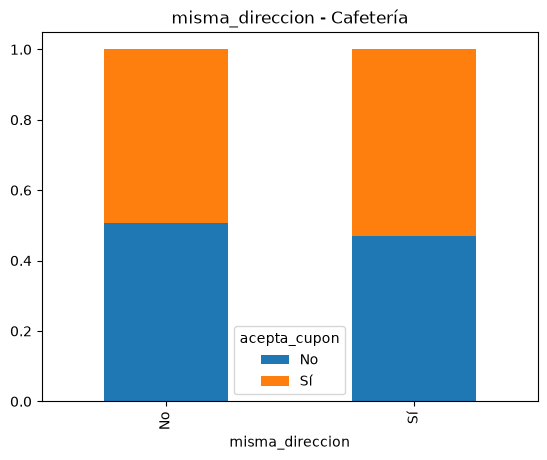

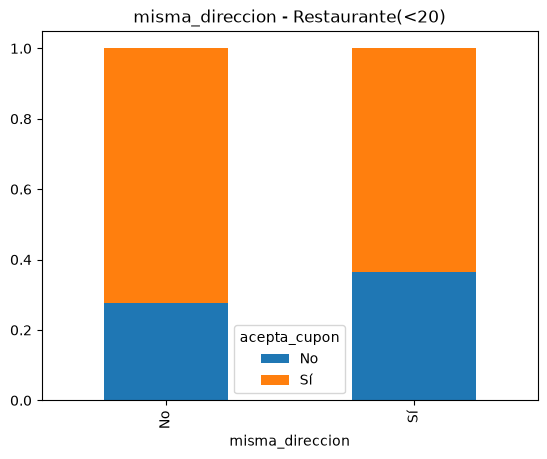

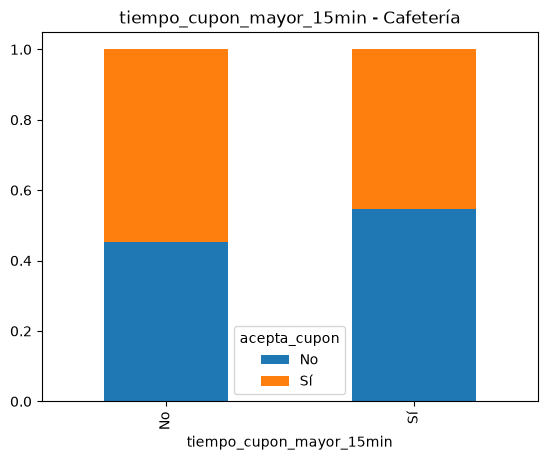

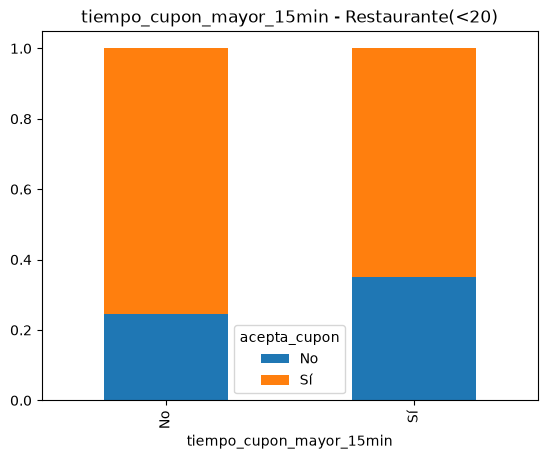

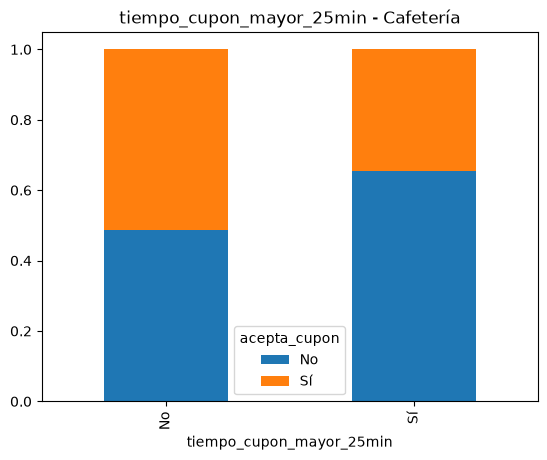

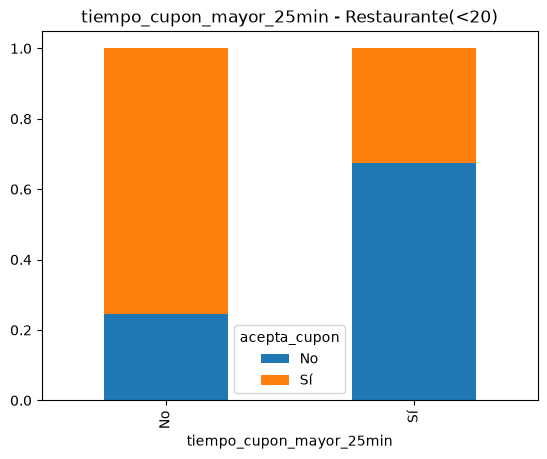

In [16]:
orden_frec = ['nunca', 'menos de 1', '1 a 3', '4 a 8', 'más de 8']

for col in ['frecuencia_bar', 'frecuencia_cafeteria', 'frecuencia_comida_para_llevar',
            'frecuencia_restaurante_menos_20', 'frecuencia_restaurante_20_a_50',
            'misma_direccion', 'tiempo_cupon_mayor_15min', 'tiempo_cupon_mayor_25min']:
    for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
        tabla = pd.crosstab(s[col], s['acepta_cupon'], normalize='index')
        if col.startswith('frecuencia'):
            tabla = tabla.reindex(orden_frec)
        tabla.plot(kind='bar', stacked=True, title=f'{col} - {nombre}')
        plt.show()

- Frecuencia de visita a cafeterias: es la variable de habitos más relacionada con el cupon de cafeteria, quienes nunca van aceptan solo el 19 %, frente a 65 a 69 % de quienes van al menos 1 a 3 veces al mes. Para eestaurante(<20) casi no hay diferencia entre 63 % y 77%.
- Frecuencia de visita a restaurantes (menos de 20 a mas de 20 y 50): en restaurante(<20) la aceptacion sube con la frecuencia de ir a restaurantes baratos, y en cafeteria tambien hay una subida suave con ambas variables.
- Frecuencia de bar y de comida para llevar: casi no cambian la aceptacion donde en cafeteria quedan entre 42 % y 52 %, por lo que no son relevantes.
- Distancia al lugar del cupón (`tiempo_cupon_mayor_25min`) es la variable con efecto mas fuerte del bloque ya que cuanod es asi la aceptacion cae a 35 % en cafeteria y a 33 % en Restaurante(<20). `tiempo_cupon_mayor_15min` muestra la misma tendencia pero mass suave.
- `misma_direccion`: tiene un efecto pequeño y en direcciones contrarias entre cupones.

## 2.7 Verificacion de consistencia y validez

Se listan las categorias de cada variable cualitativa para confirmar que coinciden con el diccionario de datos y que no hay una misma categoria escrita de dos formas, ademas se cruza `temperatura` con `clima` para ver si los valores son coherentes entre si.

In [18]:
cols_object = df_Base.select_dtypes(exclude='number').columns.drop('ocupacion')

for col in cols_object:
    print(f"--- Variable: {col} ---")
    print(df_Base[col].value_counts(dropna=False))
    print(f"Total de categorías distintas: {df_Base[col].nunique(dropna=False)}")
    print("-" * 40)

--- Variable: destino ---
destino
Sin lugar urgente    6270
Casa                 3233
Trabajo              3161
Name: count, dtype: int64
Total de categorías distintas: 3
----------------------------------------
--- Variable: acompanante ---
acompanante
Solo        7296
Amigo(s)    3291
Pareja      1072
Hijo(s)     1005
Name: count, dtype: int64
Total de categorías distintas: 4
----------------------------------------
--- Variable: clima ---
clima
Soleado     10052
Nevado       1404
Lluvioso     1208
Name: count, dtype: int64
Total de categorías distintas: 3
----------------------------------------
--- Variable: hora ---
hora
6:00 p.m.     3224
7:00 a.m.     3161
10:00 a.m.    2271
2:00 p.m.     2005
10:00 p.m.    2003
Name: count, dtype: int64
Total de categorías distintas: 5
----------------------------------------
--- Variable: cupon ---
cupon
Cafetería             3986
Restaurante(<20)      2776
Comida para llevar    2393
Bar                   2017
Restaurante(20-50)    1492
Name: 

In [19]:
print(df_Base.describe())

        temperatura
count  12664.000000
mean      63.287271
std       19.158130
min       30.000000
25%       55.000000
50%       80.000000
75%       80.000000
max       80.000000


In [20]:
pd.crosstab(df_Base['clima'], df_Base['temperatura'])

temperatura,30,55,80
clima,,,
Lluvioso,0,1208,0
Nevado,1404,0,0
Soleado,911,2628,6513


Al revisar el conteo de categorias de cada variable cualitativa se observa que todas tienen un numero de categorias coherente con el diccionario de datos y que no hay categorias escritas de dos formas distintas como mayusculas o minusculas mezcladas por lo que no es necesario normalizar el texto de las variables cualitativas. Se observan categorias con pocos registros como "Viudo(a)" en `estado_civil` y "Bachillerato incompleto" en `educacion` las cuales no se eliminan pero hay que tener presente que las conclusiones sobre ellas son menos confiables.

En cuanto a la validez, `temperatura` es la unica variable numerica y solo toma los valores 30, 55 y 80. El cruce con `clima` muestra que es coherente ya que con clima nevado solo aparece 30, con clima lluvioso solo 55 y con clima soleado aparecen los tres valores (30, 55 y 80).

## 2.8 Verificacion de variables redundantes

Se buscan variables constantes dentro de cada subconjunto y variables que repitan la misma informacion que otras.

In [21]:
for nombre, s in [('Cafetería', cafe), ('Restaurante(<20)', rest)]:
    print(nombre)
    print(s.nunique().sort_values().head(4), '\n')

Cafetería
cupon                      1
tiempo_cupon_mayor_5min    1
genero                     2
vigencia_cupon             2
dtype: int64 

Restaurante(<20)
cupon                      1
tiempo_cupon_mayor_5min    1
genero                     2
vigencia_cupon             2
dtype: int64 



In [22]:
pd.crosstab(df_Base['misma_direccion'], df_Base['direccion_opuesta'])

direccion_opuesta,No,Sí
misma_direccion,,
No,0,9944
Sí,2720,0


In [23]:
pd.crosstab([df_Base['tiempo_cupon_mayor_5min'], df_Base['tiempo_cupon_mayor_15min']],
            df_Base['tiempo_cupon_mayor_25min'])

tiempo_cupon_mayor_25min                            No    Sí
tiempo_cupon_mayor_5min tiempo_cupon_mayor_15min            
Sí                      No                        5551     0
                        Sí                        5602  1511

En ambos subconjuntos hay variables constantes: `cupon` solo tiene un valor que es el del propio subconjunto y `tiempo_cupon_mayor_5min` vale "Sí" en todos los registros por lo que no aportan información para predecir la aceptacion. Ademas, `misma_direccion` y `direccion_opuesta` son complementarias ya que cuando una es "Sí" la otra es "No" en todos los registros asi que basta con conservar una. Las variables `tiempo_cupon_mayor_5min`, `tiempo_cupon_mayor_15min` y `tiempo_cupon_mayor_25min` estan anidadas pero las de 15 y 25 minutos todavia distinguen entre lugares cercanos y lejanos por lo que se conservan.

# 3. Preparacion de los datos

Se plantea los problemas de calidad encontrados en la exploracion y las decisiones que se toman para corregirlos.

**3.1 Problemas identificados**

1. **Unicidad:** hay 7 filas duplicadas exactas en cada subconjunto (cerca del 0,2 %).
2. **Completitud:**
   - `vehiculo` tiene cerca del 99 % de valores nulos en ambos subconjuntos.
   - Las cinco variables `frecuencia_*` tienen entre 0,8 % y 1,8 % de valores nulos.
3. **Variables constantes o redundantes:**
   - `cupon` y `tiempo_cupon_mayor_5min` son constantes dentro de cada subconjunto.
   - `direccion_opuesta` es el complemento exacto de `misma_direccion`.
4. **Variables cualitativas con muchas categorías:** `ocupacion` tiene 25 categorías y varias variables (`hora`, `edad`, `educacion`, `ingreso`, `frecuencia_*`) tienen un orden natural.
5. **Desbalance de clases:** en Restaurante(<20), 70,7 % de los registros son "Sí" y 29,3 % "No"; Cafetería está balanceada (49,9 % y 50,1 %).

**3.2 Plan de procesamiento de datos**

1. **Duplicados:** eliminar las filas duplicadas exactas con `drop_duplicates()` antes de dividir en entrenamiento y prueba, para que un mismo registro no quede en ambos conjuntos.
2. **Variables a eliminar:** `vehiculo` (casi vacía), `cupon` y `tiempo_cupon_mayor_5min` (constantes) y `direccion_opuesta` (redundante con `misma_direccion`).
3. **Valores nulos:** imputar las variables `frecuencia_*` con la moda, dentro del Pipeline, calculada solo con el conjunto de entrenamiento.
4. **Codificación:**
   - Variables cualitativas (incluidas las que tienen orden natural): `OneHotEncoder`, para no imponer un orden numérico entre categorías.
   - `temperatura`: estandarización, útil para la regresión logística e inocua para árboles y bosques.
5. **Partición:** dividir cada subconjunto en 80 % entrenamiento y 20 % prueba de forma estratificada por `acepta_cupon`, con `random_state=42`.
6. **Desbalance (Restaurante(<20)):** se comparará el modelo sin balanceo con otro que use SMOTE, aplicado dentro de la validación cruzada (sección 7) para no filtrar información.

### 3.3 Implementacion

**3.3.1 Eliminacion de duplicados**

In [ ]:
df_limpio = df_Base.drop_duplicates().copy()

print('Registros despues:', len(df_limpio))
print('Duplicados eliminados:', len(df_Base) - len(df_limpio))

Registros antes: 12664
Registros despues: 12590
Duplicados eliminados: 74


**3.3.2 Eliminacion de variables y separacion por cupon**

In [26]:
cols_eliminar = ['vehiculo', 'cupon', 'tiempo_cupon_mayor_5min', 'direccion_opuesta']

cafe_l = df_limpio[df_limpio['cupon'] == 'Cafetería'].drop(columns=cols_eliminar)
rest_l = df_limpio[df_limpio['cupon'] == 'Restaurante(<20)'].drop(columns=cols_eliminar)

print('Cafetería:', cafe_l.shape)
print('Restaurante(<20):', rest_l.shape)

Cafetería: (3979, 22)
Restaurante(<20): (2769, 22)


**3.3.3 Variable objetivo y particion en entrenamiento y prueba**

Para cada cupon se separan las caracteristicas (`X`) de la variable objetivo `acepta_cupon` (`y`) y se divide en 80 % entrenamiento y 20 % prueba. Se usa `stratify=y` para mantener la misma proporcion de clases en ambos conjuntos, algo importante en restaurante(<20) que esta desbalanceado y `random_state=42` para que el resultado sea reproducible.

In [27]:
X_cafe = cafe_l.drop(columns=['acepta_cupon'])
y_cafe = cafe_l['acepta_cupon']
X_cafe_train, X_cafe_test, y_cafe_train, y_cafe_test = train_test_split(
    X_cafe, y_cafe, test_size=0.2, random_state=42, stratify=y_cafe)

X_rest = rest_l.drop(columns=['acepta_cupon'])
y_rest = rest_l['acepta_cupon']
X_rest_train, X_rest_test, y_rest_train, y_rest_test = train_test_split(
    X_rest, y_rest, test_size=0.2, random_state=42, stratify=y_rest)

print('Cafetería  - train:', X_cafe_train.shape, '| test:', X_cafe_test.shape)
print('Restaurante(<20) - train:', X_rest_train.shape, '| test:', X_rest_test.shape)
print(y_rest_train.value_counts(normalize=True).round(3))
print(y_rest_test.value_counts(normalize=True).round(3))

Cafetería  - train: (3183, 21) | test: (796, 21)
Restaurante(<20) - train: (2215, 21) | test: (554, 21)
acepta_cupon
Sí    0.707
No    0.293
Name: proportion, dtype: float64
acepta_cupon
Sí    0.708
No    0.292
Name: proportion, dtype: float64


**3.3.4 Preprocesador**

Se define un `ColumnTransformer` con las transformaciones que se usaran en todos los modelos:

- **Variables cualitativas:** primero se imputan los valores nulos con la moda y luego se codifican con `OneHotEncoder`. Las variables con orden natural (`edad`, `educacion`, `ingreso`, `hora` y `frecuencia_*`) tambien se codifican con one-hot, para no imponer un orden numerico.
- **Variable numerica (`temperatura`):** se estandariza con `StandardScaler` que es necesario para la regresion logistica y no afecta a los arboles ni al bosque.

In [28]:
categorical_features = X_cafe_train.select_dtypes(exclude='number').columns
numerical_features = X_cafe_train.select_dtypes(include='number').columns

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', drop='if_binary'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('numerical', StandardScaler(), numerical_features),
        ('categorical', categorical_transformer, categorical_features)
    ]
)

print('Variables numéricas:', list(numerical_features))
print('Variables cualitativas:', len(categorical_features))

Variables numéricas: ['temperatura']
Variables cualitativas: 20
